# Branch D motivation clustering — algorithm comparison

This notebook tests whether the motivation segmentation depends on the clustering algorithm. Every method uses the same **191 validated final-active-Branch-D respondents** and the same four ordered SDT variables.

Partitioning methods compared:

- K-medoids with ordinal Gower distance;
- average-link hierarchical clustering with Gower distance;
- complete-link hierarchical clustering with Gower distance;
- spectral clustering using a Gower-derived affinity;
- K-means on equally range-normalized ordinal codes; and
- Gaussian mixture modelling on the same normalized codes.

DBSCAN is evaluated separately because it may label respondents as noise and does not target a fixed number of clusters.

## Fair-comparison rules

1. Candidate counts 2–6 are tested for every partitioning method.
2. Every reported partition is evaluated with the **same Gower silhouette**, regardless of the fitting algorithm.
3. Stability uses 50 repeated random 80% respondent subsamples and adjusted Rand index (ARI).
4. The selected count within each algorithm minimizes an equal-weight rank of Gower silhouette and subsample stability, subject to at least 15 respondents per cluster.
5. Cross-algorithm ARI is calculated both for each method's selected solution and at a common `k=3`.
6. Euclidean metrics are included only as secondary diagnostics because K-means and GMM assume Euclidean structure.

This comparison assesses robustness; it does not guarantee that any partition represents natural psychological types.

In [1]:
from pathlib import Path
import json
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import AgglomerativeClustering, DBSCAN, KMeans, SpectralClustering
from sklearn.metrics import (
    adjusted_rand_score,
    calinski_harabasz_score,
    davies_bouldin_score,
    silhouette_samples,
    silhouette_score,
)
from sklearn.mixture import GaussianMixture

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 180)

ROOT = Path.cwd()
VALUES_PATH = ROOT / "outputs/nysc_survey_cleaned_values.csv"
LABELS_PATH = ROOT / "outputs/nysc_survey_cleaned_labels.csv"
PRIOR_ASSIGNMENTS_PATH = ROOT / "outputs/branch_d_motivation_clusters/motivation_cluster_assignments.csv"
OUT = ROOT / "outputs/branch_d_motivation_algorithm_comparison"
OUT.mkdir(parents=True, exist_ok=True)

VARIABLES = [
    "study_motivation_type",
    "autonomy_in_study",
    "competence_in_study_field",
    "relatedness_at_institution",
]
ALGORITHMS = ["kmedoids", "hac_average", "hac_complete", "spectral", "kmeans", "gmm"]
ALGORITHM_LABELS = {
    "kmedoids": "K-medoids (Gower)",
    "hac_average": "HAC average-link (Gower)",
    "hac_complete": "HAC complete-link (Gower)",
    "spectral": "Spectral (Gower affinity)",
    "kmeans": "K-means (normalized ordinal)",
    "gmm": "Gaussian mixture (normalized ordinal)",
}
RANDOM_STATE = 20260823
SUBSAMPLE_REPETITIONS = 50
SUBSAMPLE_FRACTION = 0.80
MIN_CLUSTER_SIZE = 15

## 1. Rebuild the strict cohort and distance representation

In [2]:
values_all = pd.read_csv(VALUES_PATH)
labels_all = pd.read_csv(LABELS_PATH)
strict = values_all.loc[
    values_all["branch"].eq("D")
    & values_all["branch_routing_source"].eq("translated_final_active_branch"),
    ["respondent_id", "entry_branch", "branch", "branch_routing_source"] + VARIABLES,
].copy()
readable = labels_all[["respondent_id"] + VARIABLES].copy()
cohort = strict.merge(readable, on="respondent_id", suffixes=("__code", "__label"), validate="one_to_one")
code_columns = [f"{v}__code" for v in VARIABLES]

LEVELS = {
    "study_motivation_type": 5,
    "autonomy_in_study": 4,
    "competence_in_study_field": 4,
    "relatedness_at_institution": 4,
}
validation = {
    "records": int(len(cohort)),
    "unique_ids": int(cohort["respondent_id"].nunique()),
    "wrong_branch": int(cohort["branch"].ne("D").sum()),
    "wrong_routing_source": int(cohort["branch_routing_source"].ne("translated_final_active_branch").sum()),
    "missing_codes": int(cohort[code_columns].isna().sum().sum()),
}
assert validation == {
    "records": 191, "unique_ids": 191, "wrong_branch": 0,
    "wrong_routing_source": 0, "missing_codes": 0,
}

X_codes = cohort[code_columns].to_numpy(float)
ranges = np.array([LEVELS[v] - 1 for v in VARIABLES], dtype=float)
X = (X_codes - 1) / ranges
D = np.abs(X[:, None, :] - X[None, :, :]).mean(axis=2)
np.fill_diagonal(D, 0.0)
nonzero_distances = D[D > 0]
AFFINITY_SIGMA = float(np.median(nonzero_distances))

def affinity_from_distance(distance):
    affinity = np.exp(-(distance ** 2) / (2 * AFFINITY_SIGMA ** 2))
    np.fill_diagonal(affinity, 1.0)
    return affinity

display(pd.Series(validation, name="value").to_frame())
print("Gower distance median:", round(float(np.median(nonzero_distances)), 4))
print("Gower affinity sigma:", round(AFFINITY_SIGMA, 4))

,value
records,191
unique_ids,191
wrong_branch,0
wrong_routing_source,0
missing_codes,0


Gower distance median: 0.2708
Gower affinity sigma: 0.2708


## 2. Fit functions shared by all algorithms

In [3]:
def fit_kmedoids(D, k, n_init=200, max_iter=200, random_state=RANDOM_STATE):
    rng = np.random.default_rng(random_state)
    n = len(D)
    best = None
    for _ in range(n_init):
        medoids = np.sort(rng.choice(n, size=k, replace=False))
        for _ in range(max_iter):
            labels = np.argmin(D[:, medoids], axis=1)
            updated = medoids.copy()
            for cluster in range(k):
                members = np.flatnonzero(labels == cluster)
                if len(members) == 0:
                    nearest = D[:, medoids].min(axis=1)
                    available = np.setdiff1d(np.argsort(nearest)[::-1], updated)
                    updated[cluster] = available[0]
                else:
                    within = D[np.ix_(members, members)]
                    updated[cluster] = members[np.argmin(within.sum(axis=1))]
            if np.array_equal(updated, medoids):
                break
            medoids = updated
        labels = np.argmin(D[:, medoids], axis=1)
        loss = float(D[np.arange(n), medoids[labels]].sum())
        candidate = (loss, tuple(medoids.tolist()), medoids.copy(), labels.copy())
        if best is None or candidate[:2] < best[:2]:
            best = candidate
    return {"labels": best[3], "medoids": best[2], "loss": best[0]}


def medoids_from_labels(D, labels):
    clusters = sorted(np.unique(labels))
    medoids = []
    for cluster in clusters:
        members = np.flatnonzero(labels == cluster)
        within = D[np.ix_(members, members)]
        medoids.append(members[np.argmin(within.sum(axis=1))])
    return np.asarray(medoids, dtype=int)


def fit_algorithm(name, X, D, k, random_state):
    if name == "kmedoids":
        result = fit_kmedoids(D, k, n_init=300, random_state=random_state)
        return {**result, "model": None}
    if name == "hac_average":
        model = AgglomerativeClustering(n_clusters=k, metric="precomputed", linkage="average")
        labels = model.fit_predict(D)
    elif name == "hac_complete":
        model = AgglomerativeClustering(n_clusters=k, metric="precomputed", linkage="complete")
        labels = model.fit_predict(D)
    elif name == "spectral":
        model = SpectralClustering(
            n_clusters=k, affinity="precomputed", assign_labels="kmeans",
            n_init=50, random_state=random_state,
        )
        labels = model.fit_predict(affinity_from_distance(D))
    elif name == "kmeans":
        model = KMeans(n_clusters=k, n_init=200, random_state=random_state)
        labels = model.fit_predict(X)
    elif name == "gmm":
        model = GaussianMixture(
            n_components=k, covariance_type="full", n_init=30,
            reg_covar=1e-5, random_state=random_state,
        )
        labels = model.fit_predict(X)
    else:
        raise ValueError(name)
    medoids = medoids_from_labels(D, labels)
    loss = float(D[np.arange(len(D)), medoids[np.searchsorted(np.unique(labels), labels)]].sum())
    return {"labels": labels, "medoids": medoids, "loss": loss, "model": model}


def predict_from_subsample(name, X, D, idx, k, random_state):
    X_sub = X[idx]
    D_sub = D[np.ix_(idx, idx)]
    result = fit_algorithm(name, X_sub, D_sub, k, random_state)
    if name in {"kmeans", "gmm"}:
        return result["model"].predict(X)
    global_medoids = idx[result["medoids"]]
    return np.argmin(D[:, global_medoids], axis=1)


def stability_for(name, k, reference_labels):
    rng = np.random.default_rng(RANDOM_STATE + 1000 * (ALGORITHMS.index(name) + 1) + k)
    n = len(X)
    size = int(np.floor(SUBSAMPLE_FRACTION * n))
    rows = []
    for repetition in range(SUBSAMPLE_REPETITIONS):
        idx = np.sort(rng.choice(n, size=size, replace=False))
        predicted = predict_from_subsample(
            name, X, D, idx, k,
            RANDOM_STATE + 100000 * (ALGORITHMS.index(name) + 1) + 100 * k + repetition,
        )
        rows.append({
            "algorithm": name,
            "k": k,
            "repetition": repetition + 1,
            "ari_vs_full_solution": adjusted_rand_score(reference_labels, predicted),
        })
    return pd.DataFrame(rows)

## 3. Run the full partitioning comparison

Calinski–Harabasz and Davies–Bouldin values are calculated on normalized ordinal coordinates and are secondary. Gower silhouette and subsample ARI are the primary comparable diagnostics.

In [4]:
solutions = {}
metric_rows = []
stability_parts = []

for algorithm in ALGORITHMS:
    for k in range(2, 7):
        result = fit_algorithm(
            algorithm, X, D, k,
            RANDOM_STATE + 100 * (ALGORITHMS.index(algorithm) + 1) + k,
        )
        labels = result["labels"]
        stability = stability_for(algorithm, k, labels)
        stability_parts.append(stability)
        sizes = pd.Series(labels).value_counts()
        individual = silhouette_samples(D, labels, metric="precomputed")
        solutions[(algorithm, k)] = result
        metric_rows.append({
            "algorithm": algorithm,
            "algorithm_label": ALGORITHM_LABELS[algorithm],
            "k": k,
            "silhouette_gower": silhouette_score(D, labels, metric="precomputed"),
            "subsample_ari_mean": stability["ari_vs_full_solution"].mean(),
            "subsample_ari_p10": stability["ari_vs_full_solution"].quantile(0.10),
            "calinski_harabasz_normalized": calinski_harabasz_score(X, labels),
            "davies_bouldin_normalized": davies_bouldin_score(X, labels),
            "gower_medoid_loss": result["loss"],
            "minimum_cluster_size": int(sizes.min()),
            "maximum_cluster_size": int(sizes.max()),
            "low_confidence_percent": 100 * float(np.mean(individual < 0.10)),
        })

all_metrics = pd.DataFrame(metric_rows)
all_stability = pd.concat(stability_parts, ignore_index=True)

# Same-k agreement with K-medoids.
ari_to_kmedoids = []
for algorithm in ALGORITHMS:
    for k in range(2, 7):
        ari_to_kmedoids.append({
            "algorithm": algorithm,
            "k": k,
            "ari_vs_kmedoids_same_k": adjusted_rand_score(
                solutions[("kmedoids", k)]["labels"], solutions[(algorithm, k)]["labels"]
            ),
        })
all_metrics = all_metrics.merge(pd.DataFrame(ari_to_kmedoids), on=["algorithm", "k"], how="left")

# Select k separately within each algorithm using only primary diagnostics.
selected_rows = []
for algorithm, group in all_metrics.groupby("algorithm", sort=False):
    eligible = group.loc[group["minimum_cluster_size"].ge(MIN_CLUSTER_SIZE)].copy()
    meets_size_rule = not eligible.empty
    if eligible.empty:
        eligible = group.copy()
    eligible["rank_silhouette"] = eligible["silhouette_gower"].rank(ascending=False, method="min")
    eligible["rank_stability"] = eligible["subsample_ari_mean"].rank(ascending=False, method="min")
    eligible["primary_mean_rank_within_algorithm"] = eligible[["rank_silhouette", "rank_stability"]].mean(axis=1)
    best = eligible["primary_mean_rank_within_algorithm"].min()
    selected = (
        eligible.loc[eligible["primary_mean_rank_within_algorithm"].eq(best)]
        .sort_values("k").iloc[0].copy()
    )
    selected["algorithm_has_size_eligible_candidate"] = meets_size_rule
    selected_rows.append(selected)

selected_metrics = pd.DataFrame(selected_rows).reset_index(drop=True)
selected_metrics["passes_primary_rules"] = (
    selected_metrics["silhouette_gower"].ge(0.25)
    & selected_metrics["subsample_ari_mean"].ge(0.70)
    & selected_metrics["minimum_cluster_size"].ge(MIN_CLUSTER_SIZE)
)

# Rank algorithm-selected configurations for descriptive comparison only.
selected_metrics["rank_silhouette_across_algorithms"] = selected_metrics["silhouette_gower"].rank(ascending=False, method="min")
selected_metrics["rank_stability_across_algorithms"] = selected_metrics["subsample_ari_mean"].rank(ascending=False, method="min")
selected_metrics["diagnostic_mean_rank"] = selected_metrics[[
    "rank_silhouette_across_algorithms", "rank_stability_across_algorithms"
]].mean(axis=1)
diagnostic_leader = selected_metrics.sort_values([
    "diagnostic_mean_rank", "k", "algorithm"
]).iloc[0]

print("Selected configuration within each algorithm:")
display(selected_metrics[[
    "algorithm_label", "k", "silhouette_gower", "subsample_ari_mean",
    "subsample_ari_p10", "minimum_cluster_size", "low_confidence_percent",
    "ari_vs_kmedoids_same_k", "passes_primary_rules", "diagnostic_mean_rank",
    "algorithm_has_size_eligible_candidate",
]].round(4))
print("Top diagnostic performer:", diagnostic_leader["algorithm_label"], "k=", int(diagnostic_leader["k"]))

Selected configuration within each algorithm:


,algorithm_label,k,silhouette_gower,subsample_ari_mean,subsample_ari_p10,minimum_cluster_size,low_confidence_percent,ari_vs_kmedoids_same_k,passes_primary_rules,diagnostic_mean_rank,algorithm_has_size_eligible_candidate
0,K-medoids (Gower),3,0.3517,0.9661,0.8737,46,23.5602,1.0000,True,2.5,True
1,HAC average-link (Gower),4,0.3395,0.4645,0.2411,1,12.5654,0.2853,False,5.0,False
2,HAC complete-link (Gower),2,0.3602,0.3062,0.1434,48,14.1361,0.0160,False,4.0,True
3,Spectral (Gower affinity),4,0.3477,0.7192,0.5880,28,10.9948,0.5570,True,3.5,True
4,K-means (normalized ordinal),2,0.3779,0.9830,0.9376,73,10.4712,0.1482,True,1.0,True
5,Gaussian mixture (normalized ordinal),2,0.3315,0.6342,0.1497,87,21.4660,0.1336,False,5.0,True


Top diagnostic performer: K-means (normalized ordinal) k= 2


## 4. Compare selected assignments and common-k assignments

ARI values near 1 indicate nearly identical partitions; values near 0 indicate little more agreement than chance. Agreement at common `k=3` separates algorithm differences from differences caused only by selecting different cluster counts.

In [5]:
selected_labels = {}
for row in selected_metrics.itertuples():
    selected_labels[row.algorithm] = solutions[(row.algorithm, int(row.k))]["labels"]

def ari_matrix(label_dict):
    names = list(label_dict)
    matrix = pd.DataFrame(index=names, columns=names, dtype=float)
    for a in names:
        for b in names:
            matrix.loc[a, b] = adjusted_rand_score(label_dict[a], label_dict[b])
    matrix.index = [ALGORITHM_LABELS[n] for n in matrix.index]
    matrix.columns = [ALGORITHM_LABELS[n] for n in matrix.columns]
    return matrix

selected_ari_matrix = ari_matrix(selected_labels)
k3_ari_matrix = ari_matrix({a: solutions[(a, 3)]["labels"] for a in ALGORITHMS})

off_diagonal = selected_ari_matrix.to_numpy()[~np.eye(len(selected_ari_matrix), dtype=bool)]
median_cross_algorithm_ari = float(np.median(off_diagonal))

print("ARI between each algorithm's selected configuration:")
display(selected_ari_matrix.round(3))
print("ARI with every algorithm fixed at k=3:")
display(k3_ari_matrix.round(3))
print("Median selected-solution cross-algorithm ARI:", round(median_cross_algorithm_ari, 3))

ARI between each algorithm's selected configuration:


,K-medoids (Gower),HAC average-link (Gower),HAC complete-link (Gower),Spectral (Gower affinity),K-means (normalized ordinal),Gaussian mixture (normalized ordinal)
K-medoids (Gower),1.000,0.381,0.302,0.756,0.350,0.260
HAC average-link (Gower),0.381,1.000,0.806,0.280,0.507,0.369
HAC complete-link (Gower),0.302,0.806,1.000,0.238,0.506,0.346
Spectral (Gower affinity),0.756,0.280,0.238,1.000,0.301,0.249
K-means (normalized ordinal),0.350,0.507,0.506,0.301,1.000,0.727
Gaussian mixture (normalized ordinal),0.260,0.369,0.346,0.249,0.727,1.000


ARI with every algorithm fixed at k=3:


,K-medoids (Gower),HAC average-link (Gower),HAC complete-link (Gower),Spectral (Gower affinity),K-means (normalized ordinal),Gaussian mixture (normalized ordinal)
K-medoids (Gower),1.000,0.005,0.300,0.685,0.555,0.281
HAC average-link (Gower),0.005,1.000,0.058,0.008,0.006,0.008
HAC complete-link (Gower),0.300,0.058,1.000,0.363,0.333,0.095
Spectral (Gower affinity),0.685,0.008,0.363,1.000,0.774,0.205
K-means (normalized ordinal),0.555,0.006,0.333,0.774,1.000,0.191
Gaussian mixture (normalized ordinal),0.281,0.008,0.095,0.205,0.191,1.000


Median selected-solution cross-algorithm ARI: 0.35


## 5. Compare profile outputs

Within every algorithm, profile numbers are ordered from lower to higher overall positive study orientation. This ordering makes tables easier to compare but does not force profiles from different algorithms to correspond.

In [6]:
positive = pd.DataFrame(100 * (1 - X), columns=VARIABLES)
assignment_export = cohort[["respondent_id", "entry_branch", "branch", "branch_routing_source"]].copy()
profile_mean_parts = []
profile_size_parts = []

for row in selected_metrics.itertuples():
    algorithm = row.algorithm
    k = int(row.k)
    raw = selected_labels[algorithm]
    temp = positive.copy()
    temp["raw_cluster"] = raw
    raw_means = temp.groupby("raw_cluster")[VARIABLES].mean()
    order = raw_means.mean(axis=1).sort_values().index.tolist()
    mapping = {int(old): int(i + 1) for i, old in enumerate(order)}
    ordered_labels = np.array([mapping[int(label)] for label in raw])
    assignment_export[f"{algorithm}__selected_k"] = k
    assignment_export[f"{algorithm}__profile_id"] = ordered_labels

    temp["profile_id"] = ordered_labels
    means = temp.groupby("profile_id")[VARIABLES].mean().reset_index()
    means.insert(0, "selected_k", k)
    means.insert(0, "algorithm_label", ALGORITHM_LABELS[algorithm])
    means.insert(0, "algorithm", algorithm)
    profile_mean_parts.append(means)

    sizes = pd.Series(ordered_labels).value_counts().sort_index().rename_axis("profile_id").reset_index(name="records")
    sizes["percent"] = 100 * sizes["records"] / len(cohort)
    sizes.insert(0, "selected_k", k)
    sizes.insert(0, "algorithm_label", ALGORITHM_LABELS[algorithm])
    sizes.insert(0, "algorithm", algorithm)
    profile_size_parts.append(sizes)

profile_means = pd.concat(profile_mean_parts, ignore_index=True)
profile_sizes = pd.concat(profile_size_parts, ignore_index=True)

prior_comparison_ari = None
if PRIOR_ASSIGNMENTS_PATH.exists():
    prior = pd.read_csv(PRIOR_ASSIGNMENTS_PATH, usecols=["respondent_id", "motivation_profile_id"])
    check = assignment_export[["respondent_id", "kmedoids__profile_id"]].merge(prior, on="respondent_id", validate="one_to_one")
    prior_comparison_ari = adjusted_rand_score(check["motivation_profile_id"], check["kmedoids__profile_id"])
    print("ARI between previous motivation K-medoids output and this comparison:", round(prior_comparison_ari, 4))

display(profile_sizes)
display(profile_means.round(2))

ARI between previous motivation K-medoids output and this comparison: 1.0


,algorithm,algorithm_label,selected_k,profile_id,records,percent
0,kmedoids,K-medoids (Gower),3,1,46,24.083770
1,kmedoids,K-medoids (Gower),3,2,77,40.314136
2,kmedoids,K-medoids (Gower),3,3,68,35.602094
3,hac_average,HAC average-link (Gower),4,1,2,1.047120
4,hac_average,HAC average-link (Gower),4,2,1,0.523560
5,hac_average,HAC average-link (Gower),4,3,48,25.130890
6,hac_average,HAC average-link (Gower),4,4,140,73.298429
7,hac_complete,HAC complete-link (Gower),2,1,48,25.130890
8,hac_complete,HAC complete-link (Gower),2,2,143,74.869110
9,spectral,Spectral (Gower affinity),4,1,44,23.036649


,algorithm,algorithm_label,selected_k,profile_id,study_motivation_type,autonomy_in_study,competence_in_study_field,relatedness_at_institution
0,kmedoids,K-medoids (Gower),3,1,17.93,68.12,56.52,67.39
1,kmedoids,K-medoids (Gower),3,2,81.82,71.86,58.87,68.83
2,kmedoids,K-medoids (Gower),3,3,83.09,95.10,94.12,94.12
3,hac_average,HAC average-link (Gower),4,1,62.50,33.33,0.00,0.00
4,hac_average,HAC average-link (Gower),4,2,0.00,0.00,66.67,100.00
5,hac_average,HAC average-link (Gower),4,3,22.40,70.83,56.94,64.58
6,hac_average,HAC average-link (Gower),4,4,82.68,83.33,76.67,82.86
7,hac_complete,HAC complete-link (Gower),2,1,26.04,72.92,51.39,59.03
8,hac_complete,HAC complete-link (Gower),2,2,80.59,81.35,77.39,83.68
9,spectral,Spectral (Gower affinity),4,1,18.18,70.45,56.82,65.91


## 6. Evaluate DBSCAN separately

DBSCAN can identify dense groups and noise, but its silhouette is calculated only among non-noise respondents. It is therefore not directly ranked against methods that assign everyone.

In [7]:
dbscan_rows = []
dbscan_solutions = {}
for eps in np.linspace(0.08, 0.45, 16):
    for min_samples in [5, 8, 10, 15]:
        labels = DBSCAN(eps=float(eps), min_samples=min_samples, metric="precomputed").fit_predict(D)
        nonnoise = labels >= 0
        clusters = sorted(set(labels[nonnoise]))
        n_clusters = len(clusters)
        noise_pct = 100 * float(np.mean(~nonnoise))
        if n_clusters >= 2 and nonnoise.sum() > n_clusters:
            sizes = pd.Series(labels[nonnoise]).value_counts()
            sil = silhouette_score(D[np.ix_(nonnoise, nonnoise)], labels[nonnoise], metric="precomputed")
            minimum = int(sizes.min())
            maximum = int(sizes.max())
        else:
            sil = np.nan
            minimum = 0
            maximum = 0
        key = (round(float(eps), 6), min_samples)
        dbscan_solutions[key] = labels
        dbscan_rows.append({
            "eps": float(eps), "min_samples": min_samples, "clusters": n_clusters,
            "noise_records": int((~nonnoise).sum()), "noise_percent": noise_pct,
            "silhouette_gower_nonnoise": sil,
            "minimum_nonnoise_cluster_size": minimum,
            "maximum_nonnoise_cluster_size": maximum,
        })

dbscan_metrics = pd.DataFrame(dbscan_rows)
dbscan_eligible = dbscan_metrics.loc[
    dbscan_metrics["clusters"].between(2, 6)
    & dbscan_metrics["noise_percent"].le(30)
    & dbscan_metrics["minimum_nonnoise_cluster_size"].ge(MIN_CLUSTER_SIZE)
    & dbscan_metrics["silhouette_gower_nonnoise"].notna()
].copy()

if dbscan_eligible.empty:
    dbscan_selected = None
    assignment_export["dbscan_profile_id"] = pd.NA
    print("No DBSCAN setting met the cluster-size and <=30% noise rules.")
else:
    dbscan_selected = dbscan_eligible.sort_values(
        ["silhouette_gower_nonnoise", "noise_percent"], ascending=[False, True]
    ).iloc[0]
    key = (round(float(dbscan_selected["eps"]), 6), int(dbscan_selected["min_samples"]))
    assignment_export["dbscan_profile_id"] = dbscan_solutions[key]
    print("Selected DBSCAN diagnostic setting:")
    display(dbscan_selected.to_frame("value"))

display(dbscan_metrics.sort_values(
    ["silhouette_gower_nonnoise", "noise_percent"], ascending=[False, True]
).head(15).round(4))

No DBSCAN setting met the cluster-size and <=30% noise rules.


,eps,min_samples,clusters,noise_records,noise_percent,silhouette_gower_nonnoise,minimum_nonnoise_cluster_size,maximum_nonnoise_cluster_size
3,0.0800,15,3,122,63.8743,0.7238,15,38
2,0.0800,10,6,75,39.2670,0.5578,12,38
1,0.0800,8,7,63,32.9843,0.5408,9,38
0,0.0800,5,7,60,31.4136,0.5131,9,38
28,0.2527,5,1,0,0.0000,NaN,0,0
29,0.2527,8,1,0,0.0000,NaN,0,0
30,0.2527,10,1,0,0.0000,NaN,0,0
31,0.2527,15,1,0,0.0000,NaN,0,0
32,0.2773,5,1,0,0.0000,NaN,0,0
33,0.2773,8,1,0,0.0000,NaN,0,0


## 7. Visual comparisons

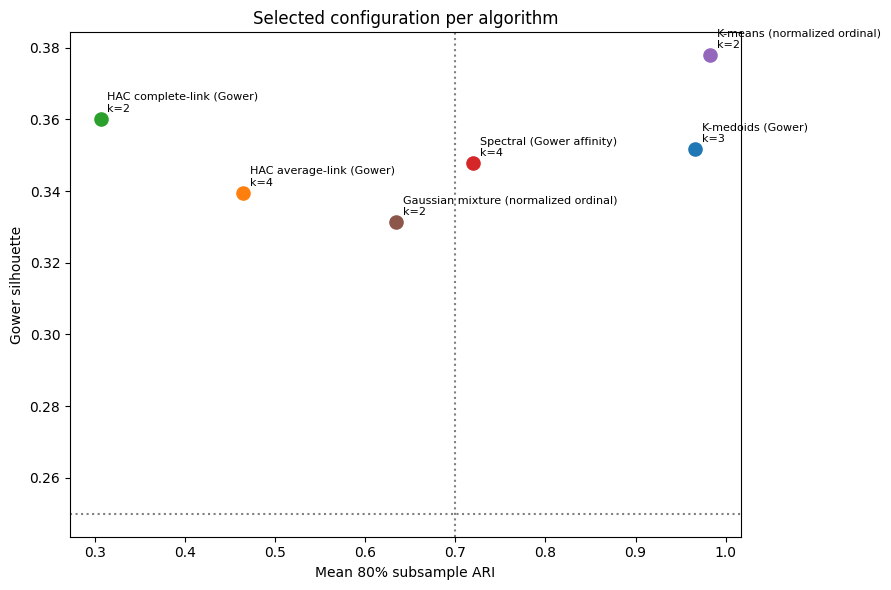

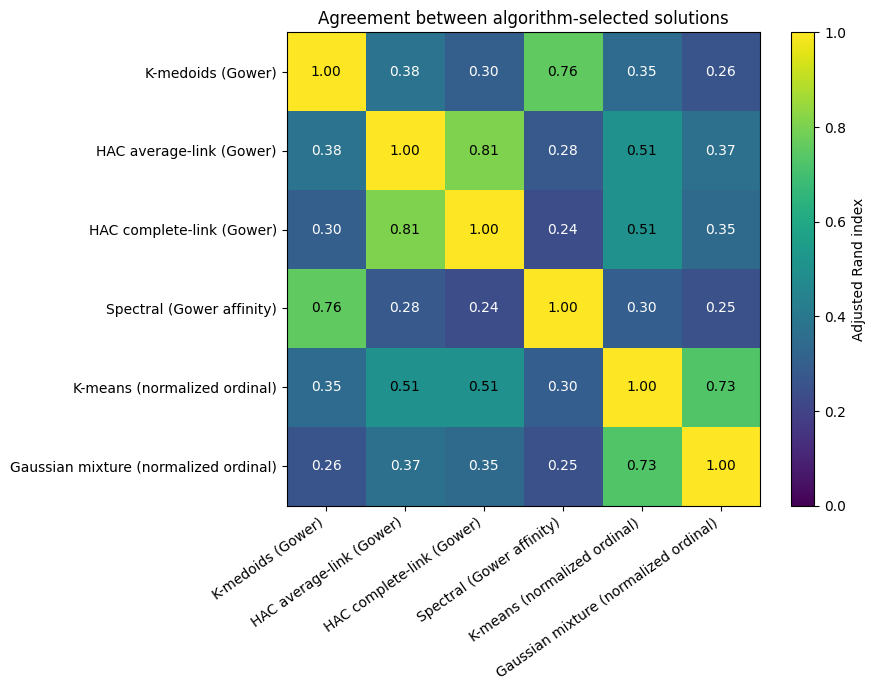

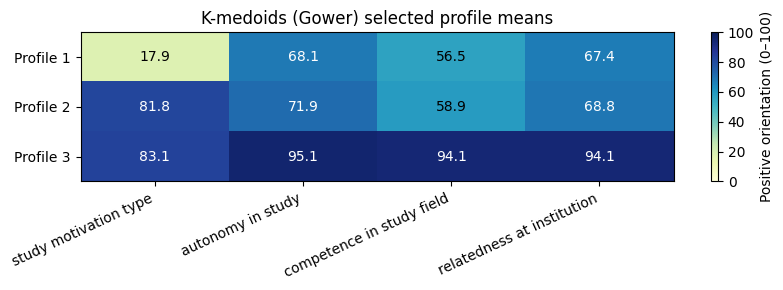

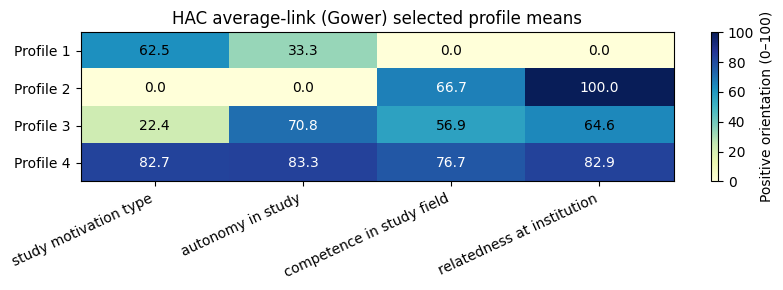

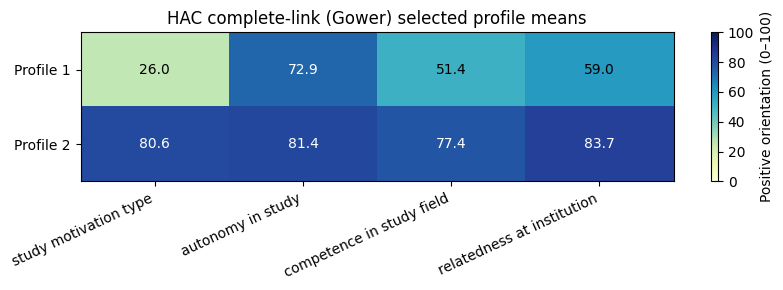

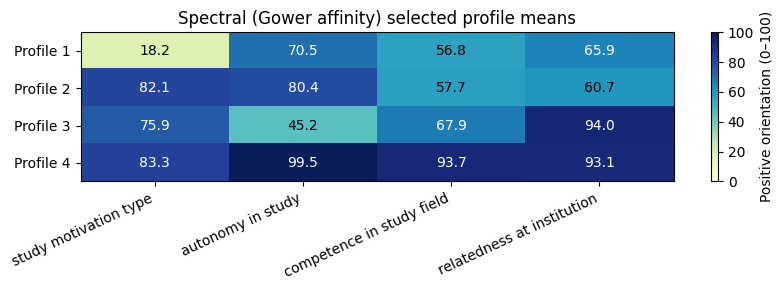

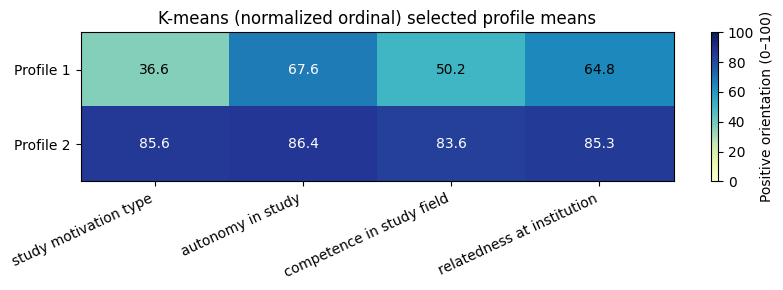

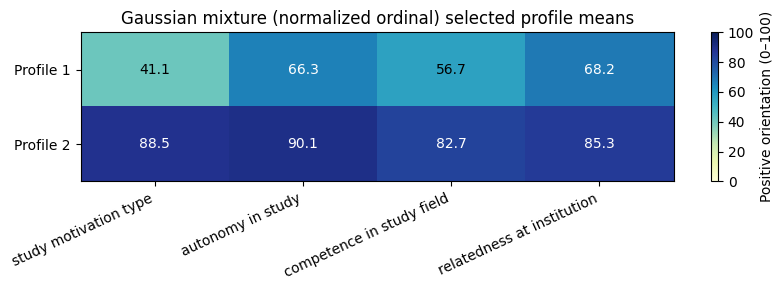

In [8]:
fig, ax = plt.subplots(figsize=(9, 6))
for row in selected_metrics.itertuples():
    ax.scatter(row.subsample_ari_mean, row.silhouette_gower, s=90)
    ax.annotate(f"{row.algorithm_label}\nk={int(row.k)}", (row.subsample_ari_mean, row.silhouette_gower),
                xytext=(5, 5), textcoords="offset points", fontsize=8)
ax.axvline(0.70, color="grey", linestyle=":")
ax.axhline(0.25, color="grey", linestyle=":")
ax.set(xlabel="Mean 80% subsample ARI", ylabel="Gower silhouette",
       title="Selected configuration per algorithm")
fig.tight_layout()
fig.savefig(OUT / "selected_algorithm_diagnostics.png", dpi=180, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(9, 7))
heat = ax.imshow(selected_ari_matrix.to_numpy(), cmap="viridis", vmin=0, vmax=1)
ax.set_xticks(range(len(selected_ari_matrix)), selected_ari_matrix.columns, rotation=35, ha="right")
ax.set_yticks(range(len(selected_ari_matrix)), selected_ari_matrix.index)
for i in range(len(selected_ari_matrix)):
    for j in range(len(selected_ari_matrix)):
        value = selected_ari_matrix.iloc[i, j]
        ax.text(j, i, f"{value:.2f}", ha="center", va="center", color="white" if value < 0.45 else "black")
fig.colorbar(heat, ax=ax, label="Adjusted Rand index")
ax.set_title("Agreement between algorithm-selected solutions")
fig.tight_layout()
fig.savefig(OUT / "selected_algorithm_ari_heatmap.png", dpi=180, bbox_inches="tight")
plt.show()

for algorithm in ALGORITHMS:
    subset = profile_means.loc[profile_means["algorithm"].eq(algorithm)].set_index("profile_id")[VARIABLES]
    fig, ax = plt.subplots(figsize=(8.5, max(3.0, len(subset) * 0.65)))
    heat = ax.imshow(subset.to_numpy(), cmap="YlGnBu", vmin=0, vmax=100, aspect="auto")
    ax.set_xticks(range(len(VARIABLES)), [v.replace("_", " ") for v in VARIABLES], rotation=25, ha="right")
    ax.set_yticks(range(len(subset)), [f"Profile {i}" for i in subset.index])
    for i in range(len(subset)):
        for j in range(len(VARIABLES)):
            val = subset.iloc[i, j]
            ax.text(j, i, f"{val:.1f}", ha="center", va="center", color="white" if val > 65 else "black")
    ax.set_title(f"{ALGORITHM_LABELS[algorithm]} selected profile means")
    fig.colorbar(heat, ax=ax, label="Positive orientation (0–100)")
    fig.tight_layout()
    fig.savefig(OUT / f"{algorithm}_selected_profile_heatmap.png", dpi=180, bbox_inches="tight")
    plt.show()

## 8. Save outputs and comparison conclusion

In [9]:
all_metrics.to_csv(OUT / "motivation_all_algorithm_k_metrics.csv", index=False)
all_stability.to_csv(OUT / "motivation_all_algorithm_subsample_stability.csv", index=False)
selected_metrics.to_csv(OUT / "motivation_selected_algorithm_metrics.csv", index=False)
selected_ari_matrix.to_csv(OUT / "motivation_selected_algorithm_ari_matrix.csv")
k3_ari_matrix.to_csv(OUT / "motivation_common_k3_ari_matrix.csv")
assignment_export.to_csv(OUT / "motivation_multi_algorithm_assignments.csv", index=False)
profile_means.to_csv(OUT / "motivation_multi_algorithm_profile_means.csv", index=False)
profile_sizes.to_csv(OUT / "motivation_multi_algorithm_profile_sizes.csv", index=False)
dbscan_metrics.to_csv(OUT / "motivation_dbscan_grid_metrics.csv", index=False)

selected_configurations = {}
for row in selected_metrics.itertuples():
    selected_configurations[row.algorithm] = {
        "algorithm_label": row.algorithm_label,
        "k": int(row.k),
        "silhouette_gower": float(row.silhouette_gower),
        "subsample_ari_mean": float(row.subsample_ari_mean),
        "subsample_ari_p10": float(row.subsample_ari_p10),
        "minimum_cluster_size": int(row.minimum_cluster_size),
        "low_confidence_percent": float(row.low_confidence_percent),
        "ari_vs_kmedoids_same_k": float(row.ari_vs_kmedoids_same_k),
        "passes_primary_rules": bool(row.passes_primary_rules),
    }

if median_cross_algorithm_ari >= 0.60:
    robustness_status = "Broad cross-algorithm agreement"
elif median_cross_algorithm_ari >= 0.40:
    robustness_status = "Moderate cross-algorithm agreement"
else:
    robustness_status = "Low cross-algorithm agreement — cluster interpretation is method-dependent"

summary = {
    "cohort": {
        "records": int(len(cohort)),
        "branch": "D",
        "routing_source": "translated_final_active_branch",
        "variables": VARIABLES,
    },
    "comparison": {
        "algorithms": ALGORITHM_LABELS,
        "candidate_k": [2, 3, 4, 5, 6],
        "subsample_repetitions_per_configuration": SUBSAMPLE_REPETITIONS,
        "selected_configurations": selected_configurations,
        "diagnostic_leader": {
            "algorithm": diagnostic_leader["algorithm"],
            "algorithm_label": diagnostic_leader["algorithm_label"],
            "k": int(diagnostic_leader["k"]),
        },
        "median_selected_solution_cross_algorithm_ari": median_cross_algorithm_ari,
        "robustness_status": robustness_status,
        "prior_kmedoids_reproduction_ari": None if prior_comparison_ari is None else float(prior_comparison_ari),
    },
    "dbscan": None if dbscan_selected is None else {
        "eps": float(dbscan_selected["eps"]),
        "min_samples": int(dbscan_selected["min_samples"]),
        "clusters": int(dbscan_selected["clusters"]),
        "noise_records": int(dbscan_selected["noise_records"]),
        "noise_percent": float(dbscan_selected["noise_percent"]),
        "silhouette_gower_nonnoise": float(dbscan_selected["silhouette_gower_nonnoise"]),
    },
    "interpretation": (
        "Compare algorithm-specific profiles and do not adopt a final motivation typology unless "
        "the cross-method agreement and substantive interpretation are acceptable."
    ),
}

with open(OUT / "motivation_algorithm_comparison_summary.json", "w", encoding="utf-8") as handle:
    json.dump(summary, handle, indent=2)

print(json.dumps(summary, indent=2))
print("\nSaved files:")
for path in sorted(OUT.iterdir()):
    print(" -", path.name)

{
  "cohort": {
    "records": 191,
    "branch": "D",
    "routing_source": "translated_final_active_branch",
    "variables": [
      "study_motivation_type",
      "autonomy_in_study",
      "competence_in_study_field",
      "relatedness_at_institution"
    ]
  },
  "comparison": {
    "algorithms": {
      "kmedoids": "K-medoids (Gower)",
      "hac_average": "HAC average-link (Gower)",
      "hac_complete": "HAC complete-link (Gower)",
      "spectral": "Spectral (Gower affinity)",
      "kmeans": "K-means (normalized ordinal)",
      "gmm": "Gaussian mixture (normalized ordinal)"
    },
    "candidate_k": [
      2,
      3,
      4,
      5,
      6
    ],
    "subsample_repetitions_per_configuration": 50,
    "selected_configurations": {
      "kmedoids": {
        "algorithm_label": "K-medoids (Gower)",
        "k": 3,
        "silhouette_gower": 0.35172802787566665,
        "subsample_ari_mean": 0.9660517379853207,
        "subsample_ari_p10": 0.873734105523781,
        "min

## Interpretation guardrails

- Higher silhouette or stability does not prove that a method discovered the true psychological groups.
- K-means and GMM impose stronger numerical/distributional assumptions than Gower-based methods.
- DBSCAN's non-noise silhouette cannot be directly compared with full-partition silhouettes.
- If different methods produce low ARI, report the segmentation as algorithm-dependent even when one method is internally stable.
- Profile means are descriptive 0–100 positive-orientation transformations of the original ordered responses; clustering never used a composite motivation score.